In [4]:
# imports
import pandas as pd, numpy as np, os
from sqlalchemy import create_engine

# dirs
os.makedirs("../data/processed", exist_ok=True)

# 1. fund master
df_master = pd.read_csv("../data/raw/01_fund_master.csv")
print("==== FUND MASTER SUMMARY ====")
print("Fund Houses:", len(df_master['fund_house'].unique()))
print("Categories:", len(df_master['category'].unique()))
print("Sub-categories:", len(df_master['sub_category'].unique()))
print("Risk Categories:", len(df_master['risk_category'].unique()))

# FIX: Master file ko save karna zaroori hai taaki DB load ke waqt error na aaye
df_master.drop_duplicates().to_csv("../data/processed/clean_fund_master.csv", index=False)

# 2. nav clean
df_nav = pd.read_csv("../data/raw/02_nav_history.csv")
df_nav['date'] = pd.to_datetime(df_nav['date'])
df_nav = df_nav.sort_values(['amfi_code', 'date']).drop_duplicates(['amfi_code', 'date']).reset_index(drop=True)
df_nav['nav'] = df_nav.groupby('amfi_code')['nav'].ffill()
print("\n==== NAV SUMMARY ====")
print("NAV rows:", len(df_nav), "Invalid NAV:", (df_nav['nav'] <= 0).sum())
df_nav.to_csv("../data/processed/clean_nav.csv", index=False)

# 3. transactions
df_tx = pd.read_csv("../data/raw/08_investor_transactions.csv")
df_tx['transaction_type'] = df_tx['transaction_type'].str.strip().str.upper()
df_tx = df_tx[df_tx['amount_inr'] > 0]
if 'kyc_status' in df_tx.columns: 
    df_tx['kyc_status'] = df_tx['kyc_status'].str.strip().str.upper()
df_tx['transaction_date'] = pd.to_datetime(df_tx['transaction_date'])
df_tx.to_csv("../data/processed/clean_transactions.csv", index=False)

# 4. performance
df_perf = pd.read_csv("../data/raw/07_scheme_performance.csv")
for c in ['return_1yr', 'return_3yr', 'return_5yr']: 
    if c in df_perf.columns: 
        df_perf[c] = pd.to_numeric(df_perf[c], errors='coerce')
if 'sharpe_ratio' in df_perf.columns: 
    df_perf['sharpe_ratio'] = pd.to_numeric(df_perf['sharpe_ratio'], errors='coerce')
    df_perf['is_negative_sharpe'] = df_perf['sharpe_ratio'] < 0
df_perf.to_csv("../data/processed/clean_performance.csv", index=False)

# 5. remaining files
remaining = {
    "03_aum_by_fund_house.csv": "clean_aum.csv",
    "04_monthly_sip_inflows.csv": "clean_sip_inflows.csv",
    "05_category_inflows.csv": "clean_category_inflows.csv",
    "06_industry_folio_count.csv": "clean_folio_count.csv",
    "09_portfolio_holdings.csv": "clean_portfolio.csv",
    "10_benchmark_indices.csv": "clean_benchmarks.csv"
}
for raw, clean in remaining.items():
    try: 
        pd.read_csv(f"../data/raw/{raw}").drop_duplicates().to_csv(f"../data/processed/{clean}", index=False)
    except Exception as e: 
        print("Error processing file:", raw, e)

# 6. db load
print("\n==== LOADING DATA INTO SQLITE DATABASE ====")
engine = create_engine('sqlite:///../bluestock_mf.db')
db_tables = {
    "clean_fund_master.csv": "dim_fund",
    "clean_nav.csv": "fact_nav",
    "clean_transactions.csv": "fact_transactions",
    "clean_performance.csv": "fact_performance"
}

for f, t in db_tables.items():
    try:
        df_to_load = pd.read_csv(f"../data/processed/{f}")
        df_to_load.to_sql(t, engine, if_exists='replace', index=False)
        print(f"Successfully loaded {t} from {f}")
    except Exception as e:
        print(f"Error loading {t}: {e}")


==== FUND MASTER SUMMARY ====
Fund Houses: 10
Categories: 2
Sub-categories: 12
Risk Categories: 5

==== NAV SUMMARY ====
NAV rows: 46000 Invalid NAV: 0

==== LOADING DATA INTO SQLITE DATABASE ====
Successfully loaded dim_fund from clean_fund_master.csv
Successfully loaded fact_nav from clean_nav.csv
Successfully loaded fact_transactions from clean_transactions.csv
Successfully loaded fact_performance from clean_performance.csv


==== DAY 3: EDA INITIALIZED SUCCESSFULLY ====



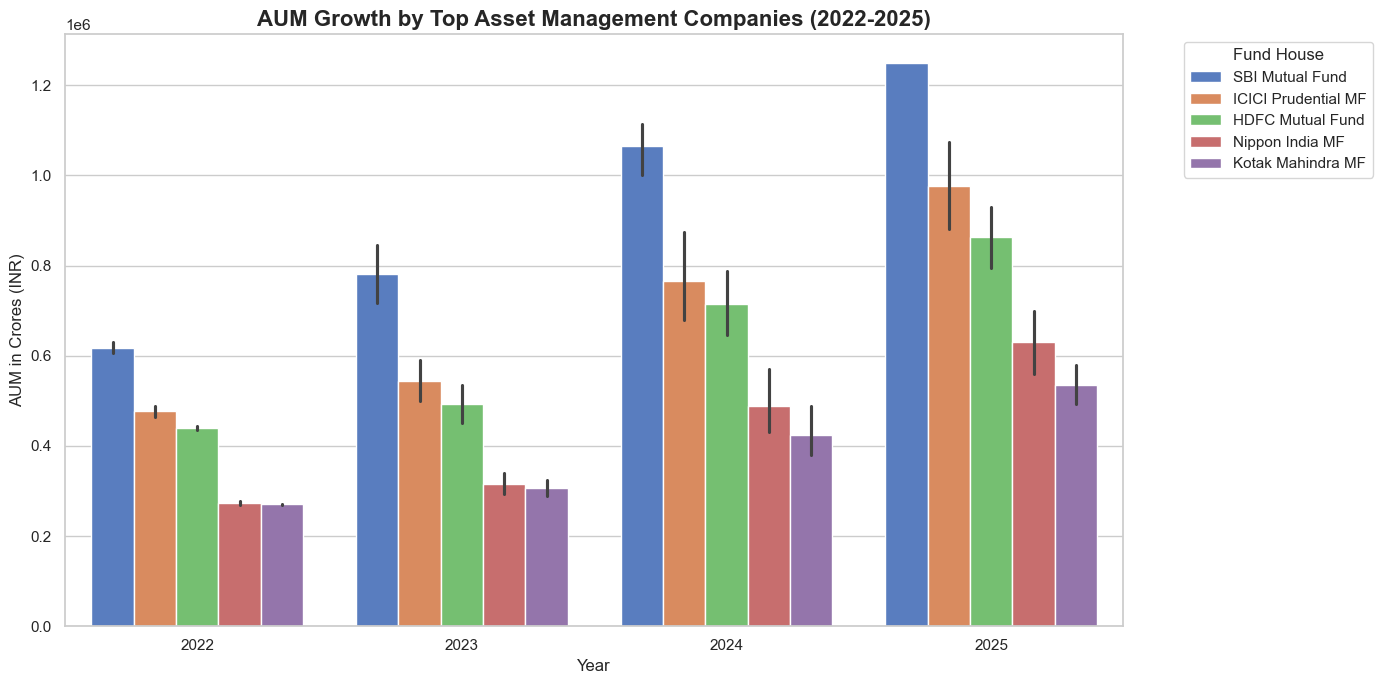

[SUCCESS] Chart 2: AUM Growth Bar Chart created and saved!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# 1. Database Connection setup
engine = create_engine('sqlite:///../bluestock_mf.db')

# Styling Setup for publication-quality charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("==== DAY 3: EDA INITIALIZED SUCCESSFULLY ====\n")

# --- CHART 2: AUM Growth by AMC (Grouped Bar Chart) ---
try:
    # Query AUM Data from DB
    query_aum = "SELECT fund_house, date as year, aum_crore FROM fact_aum;"
    df_aum = pd.read_sql(query_aum, engine)
    
    # Cleaning year string to just get the year number if needed
    df_aum['year'] = df_aum['year'].astype(str).str[:4]
    
    # Top 5 AMCs filters to avoid overcrowding the chart
    top_amcs = df_aum.groupby('fund_house')['aum_crore'].mean().nlargest(5).index
    df_aum_top = df_aum[df_aum['fund_house'].isin(top_amcs)]

    plt.figure(figsize=(14, 7))
    sns.barplot(data=df_aum_top, x='year', y='aum_crore', hue='fund_house', palette='muted')
    plt.title("AUM Growth by Top Asset Management Companies (2022-2025)", fontsize=16, fontweight='bold')
    plt.xlabel("Year", fontsize=12)
    plt.ylabel("AUM in Crores (INR)", fontsize=12)
    plt.legend(title="Fund House", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    
    # Save chart as PNG
    plt.savefig('aum_growth_amc.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 2: AUM Growth Bar Chart created and saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 2: {e}")

==== CREATING CHART 1: NAV TREND LINES ====



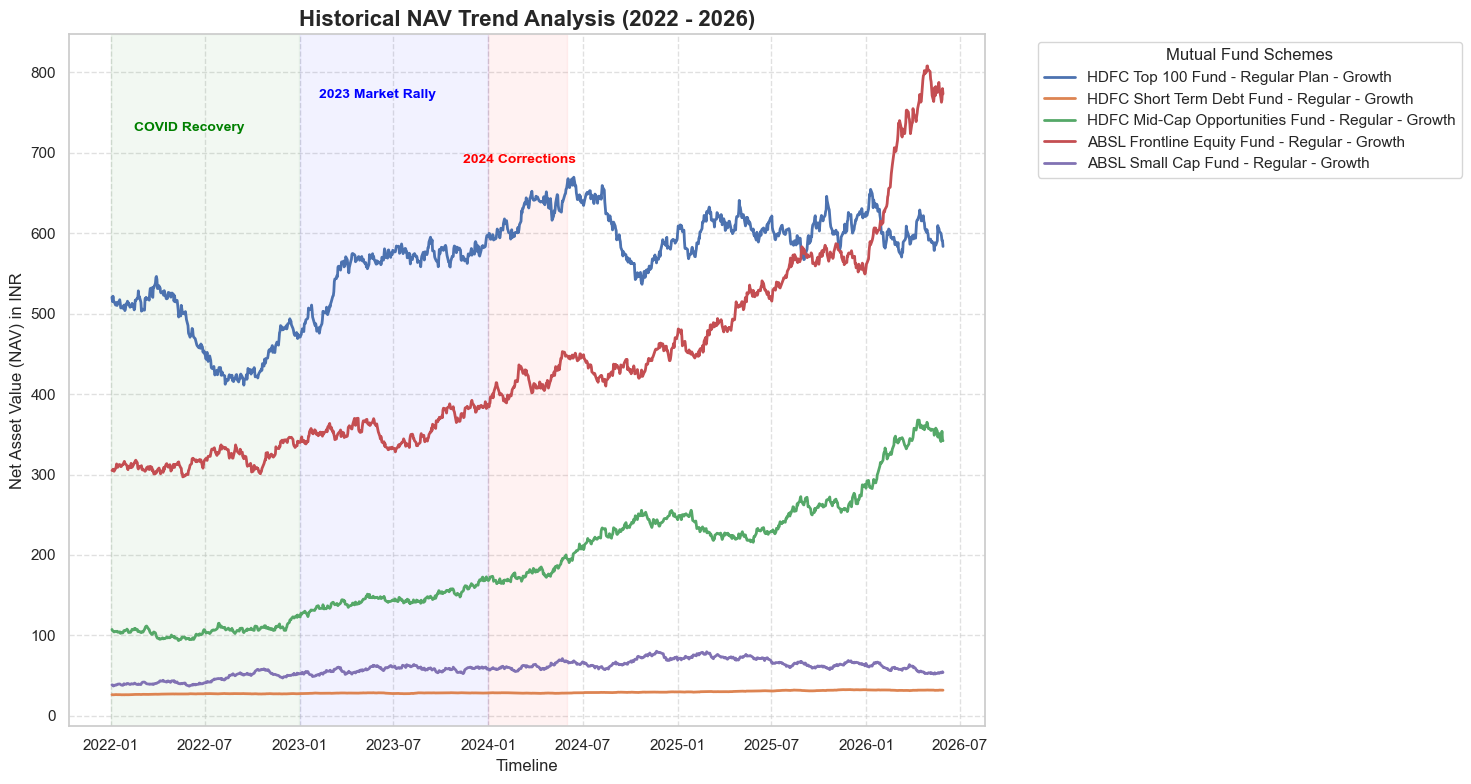

[SUCCESS] Chart 1: NAV Trend Lines created and saved successfully!


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Database Connection
engine = create_engine('sqlite:///../bluestock_mf.db')

print("==== CREATING CHART 1: NAV TREND LINES ====\n")

try:
    # 1. Fetch Daily NAV data joined with Scheme Names
    query_nav = """
    SELECT f.scheme_name, f.category, n.date, n.nav
    FROM fact_nav n
    JOIN dim_fund f ON n.amfi_code = f.amfi_code
    ORDER BY n.date ASC;
    """
    df_nav = pd.read_sql(query_nav, engine)
    df_nav['date'] = pd.to_datetime(df_nav['date'])
    
    # Filter 4-5 major representative funds to keep the chart clean and professional
    unique_funds = df_nav['scheme_name'].unique()
    selected_funds = unique_funds[:5] # Picking top 5 schemes for clear visibility
    df_nav_filtered = df_nav[df_nav['scheme_name'].isin(selected_funds)]
    
    # 2. Plotting the Chart
    plt.figure(figsize=(15, 8))
    sns.lineplot(data=df_nav_filtered, x='date', y='nav', hue='scheme_name', linewidth=2)
    
    # 3. Highlighting Market Phases (As per Guidelines)
    # Phase 1: COVID Recovery / Growth (2022)
    plt.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'), color='green', alpha=0.05)
    plt.text(pd.Timestamp('2022-06-01'), df_nav_filtered['nav'].max()*0.9, 'COVID Recovery', 
             fontsize=10, color='green', weight='bold', horizontalalignment='center')
    
    # Phase 2: 2023 Mega Rally
    plt.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'), color='blue', alpha=0.05)
    plt.text(pd.Timestamp('2023-06-01'), df_nav_filtered['nav'].max()*0.95, '2023 Market Rally', 
             fontsize=10, color='blue', weight='bold', horizontalalignment='center')
    
    # Phase 3: 2024 Market Corrections
    plt.axvspan(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-06-01'), color='red', alpha=0.05)
    plt.text(pd.Timestamp('2024-03-01'), df_nav_filtered['nav'].max()*0.85, '2024 Corrections', 
             fontsize=10, color='red', weight='bold', horizontalalignment='center')

    # Chart Details
    plt.title("Historical NAV Trend Analysis (2022 - 2026)", fontsize=16, fontweight='bold')
    plt.xlabel("Timeline", fontsize=12)
    plt.ylabel("Net Asset Value (NAV) in INR", fontsize=12)
    plt.legend(title="Mutual Fund Schemes", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    
    # Save the chart
    plt.savefig('nav_trend_analysis.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 1: NAV Trend Lines created and saved successfully!")
    
except Exception as e:
    print(f"[ERROR] Creating Chart 1: {e}")

==== CREATING CHART 3 & CHART 4 ====



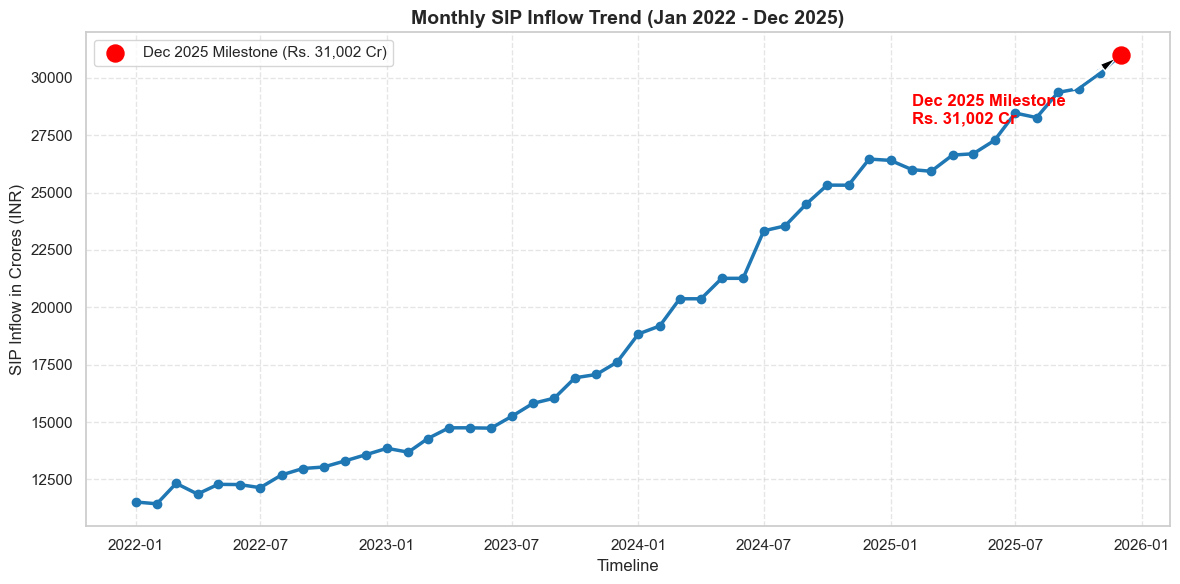

[SUCCESS] Chart 3: SIP Inflow Time-Series created and saved!


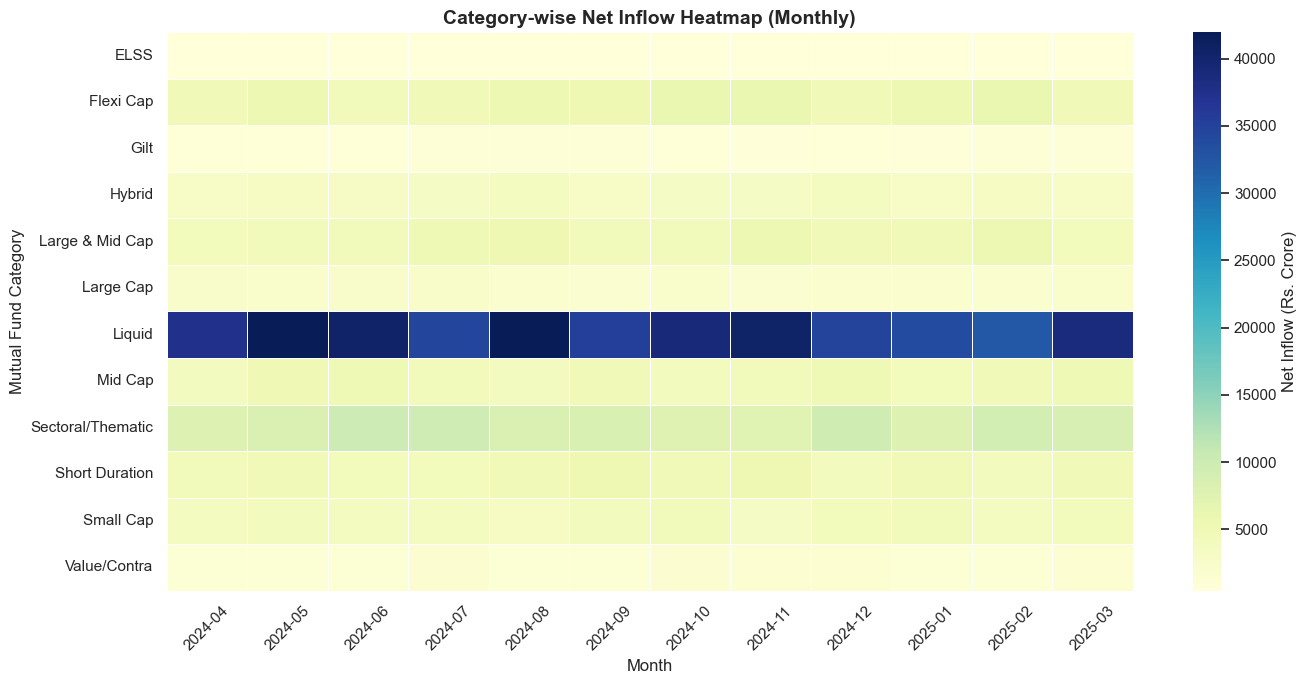

[SUCCESS] Chart 4: Category Heatmap created and saved!


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Database Connection
engine = create_engine('sqlite:///../bluestock_mf.db')

print("==== CREATING CHART 3 & CHART 4 ====\n")

# --- CHART 3: SIP Inflow Time-Series ---
try:
    # Fetch SIP data
    query_sip = "SELECT month, sip_inflow_crore FROM fact_sip_industry ORDER BY month ASC;"
    df_sip = pd.read_sql(query_sip, engine)
    df_sip['month'] = pd.to_datetime(df_sip['month'])
    
    plt.figure(figsize=(12, 6))
    plt.plot(df_sip['month'], df_sip['sip_inflow_crore'], marker='o', color='#1f77b4', linewidth=2.5)
    
    # Milestone Highlight: Rs. 31,002 Cr in Dec 2025 (As per objectives)
    milestone_date = pd.Timestamp('2025-12-01')
    milestone_val = 31002.0
    
    plt.scatter(milestone_date, milestone_val, color='red', s=150, zorder=5, label='Dec 2025 Milestone (Rs. 31,002 Cr)')
    plt.annotate('Dec 2025 Milestone\nRs. 31,002 Cr', 
                 xy=(milestone_date, milestone_val), 
                 xytext=(pd.Timestamp('2025-02-01'), milestone_val - 3000),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
                 fontweight='bold', color='red')

    plt.title("Monthly SIP Inflow Trend (Jan 2022 - Dec 2025)", fontsize=14, fontweight='bold')
    plt.xlabel("Timeline", fontsize=12)
    plt.ylabel("SIP Inflow in Crores (INR)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig('sip_inflow_trend.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 3: SIP Inflow Time-Series created and saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 3: {e}")

# --- CHART 4: Category-wise Inflow Heatmap ---
try:
    # Fetch Category Inflows data
    query_cat = "SELECT month, category, net_inflow_crore FROM fact_category_inflows;"
    df_cat = pd.read_sql(query_cat, engine)
    
    # Pivot the data: Months on X-axis, Categories on Y-axis
    df_pivot = df_cat.pivot(index='category', columns='month', values='net_inflow_crore')
    
    plt.figure(figsize=(14, 7))
    sns.heatmap(df_pivot, cmap='YlGnBu', annot=False, linewidths=.5, cbar_kws={'label': 'Net Inflow (Rs. Crore)'})
    plt.title("Category-wise Net Inflow Heatmap (Monthly)", fontsize=14, fontweight='bold')
    plt.xlabel("Month", fontsize=12)
    plt.ylabel("Mutual Fund Category", fontsize=12)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('category_inflow_heatmap.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 4: Category Heatmap created and saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 4: {e}")

==== CREATING DEMOGRAPHICS & GEOGRAPHIC CHARTS (TASK 5 & 6) ====



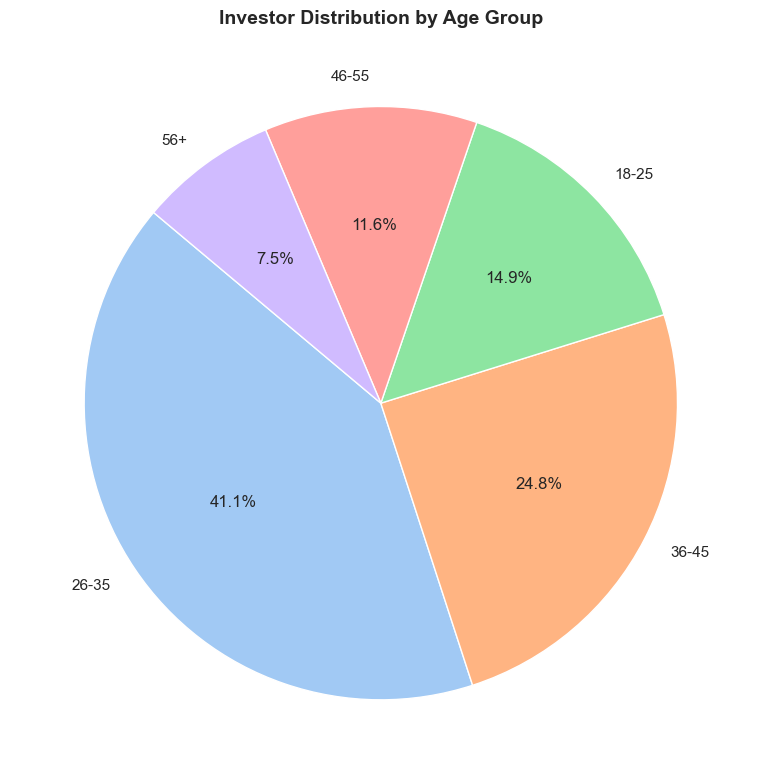

[SUCCESS] Chart 5: Age Distribution Pie Chart saved!


C:\Users\Hp\AppData\Local\Temp\ipykernel_9576\4051868917.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_inflow, x='age_group', y='amount_inr', palette='Set2')


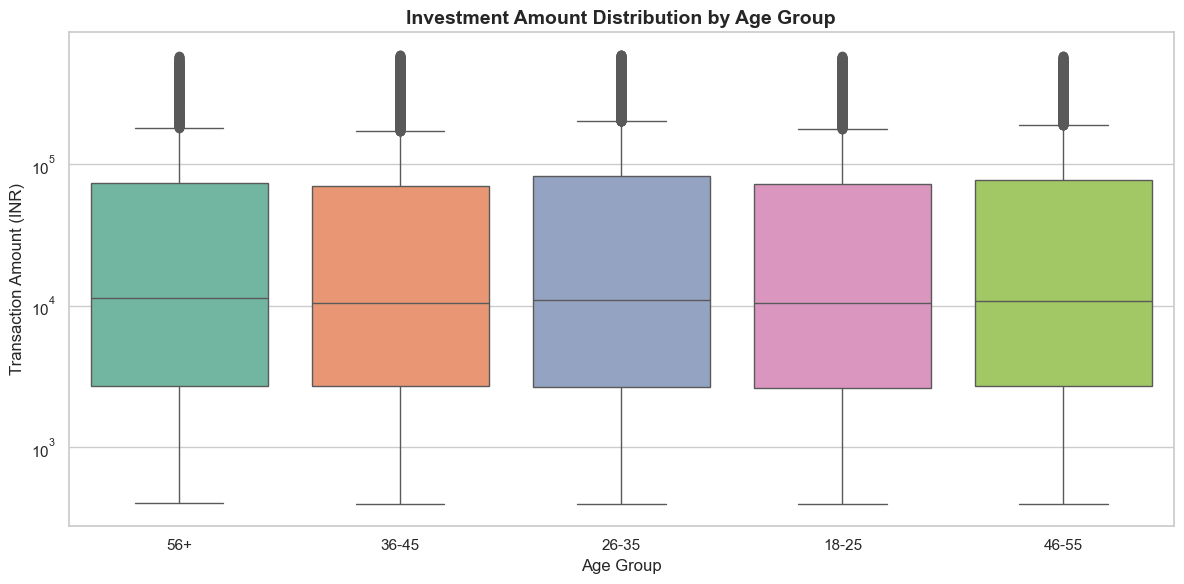

[SUCCESS] Chart 6: Investment Amount Boxplot saved!


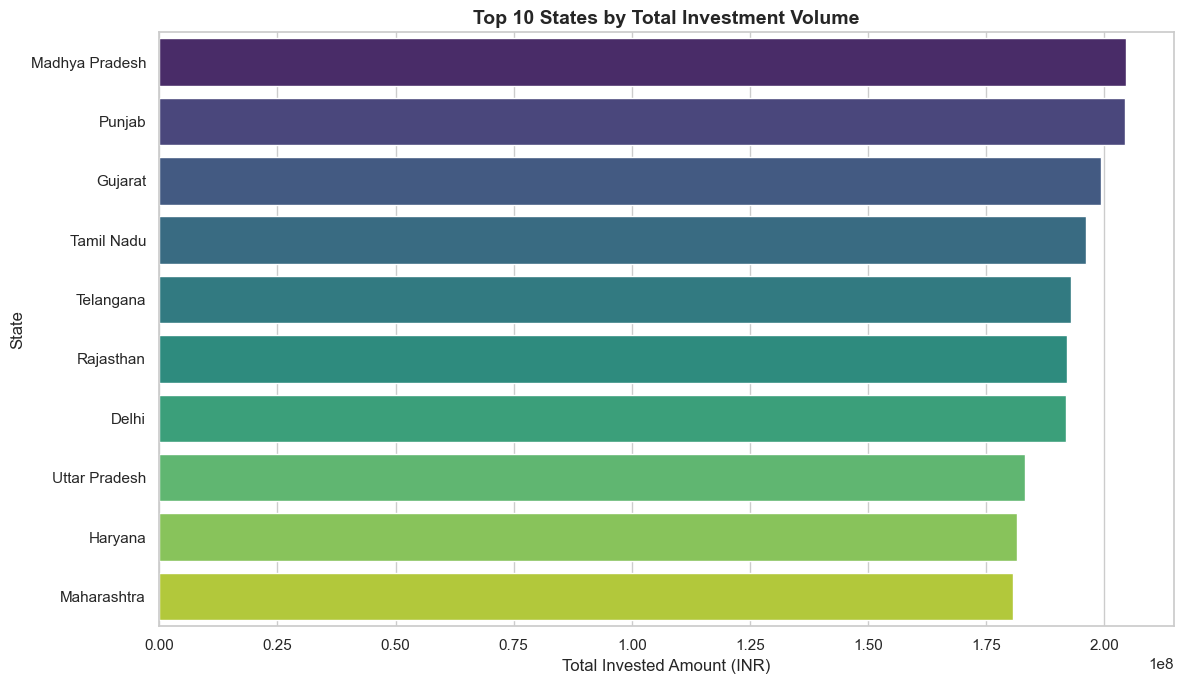

[SUCCESS] Chart 7: State Distribution Bar Chart saved!


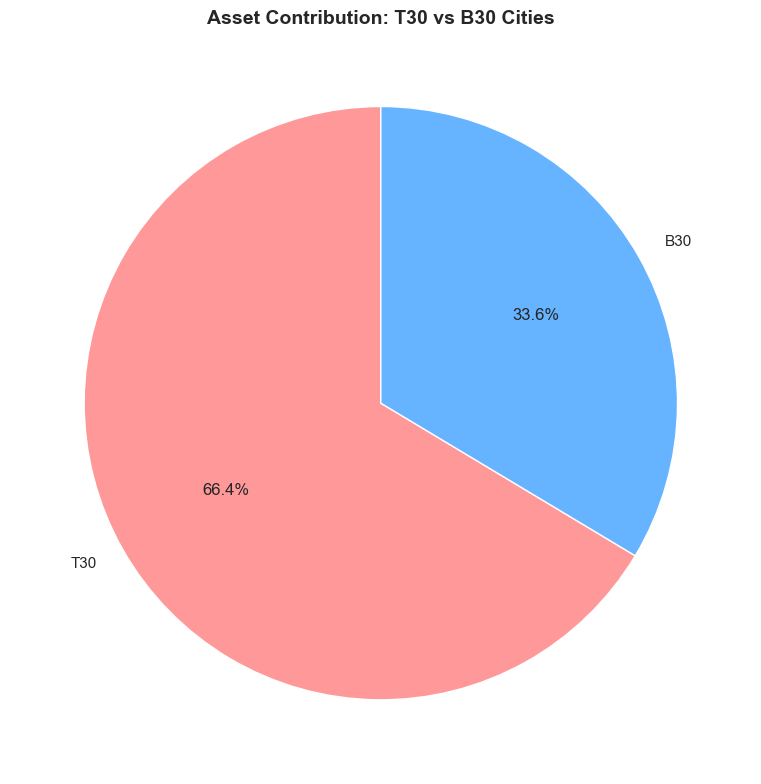

[SUCCESS] Chart 8: T30 vs B30 Pie Chart saved!


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Database Connection
engine = create_engine('sqlite:///../bluestock_mf.db')

print("==== CREATING DEMOGRAPHICS & GEOGRAPHIC CHARTS (TASK 5 & 6) ====\n")

# Fetch Investor Transaction Data from Database
query_tx = "SELECT age_group, amount_inr, state, city_tier, transaction_type FROM fact_transactions;"
df_tx = pd.read_sql(query_tx, engine)

# Filter for only Inflows (SIP & Lumpsum) for clean demographic analysis
df_inflow = df_tx[df_tx['transaction_type'].isin(['SIP', 'LUMPSUM'])].copy()

# --- CHART 5: Age Group Distribution (Pie Chart) ---
try:
    age_counts = df_inflow['age_group'].value_counts()
    
    plt.figure(figsize=(8, 8))
    plt.pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
    plt.title("Investor Distribution by Age Group", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('investor_age_pie.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 5: Age Distribution Pie Chart saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 5: {e}")

# --- CHART 6: SIP Amount Box Plot by Age Group ---
try:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df_inflow, x='age_group', y='amount_inr', palette='Set2')
    plt.title("Investment Amount Distribution by Age Group", fontsize=14, fontweight='bold')
    plt.xlabel("Age Group", fontsize=12)
    plt.ylabel("Transaction Amount (INR)", fontsize=12)
    plt.yscale('log') # Using log scale to better visualize variations across ranges
    plt.tight_layout()
    plt.savefig('investor_amount_boxplot.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 6: Investment Amount Boxplot saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 6: {e}")

# --- CHART 7: SIP Amount by State (Horizontal Bar Chart) ---
try:
    state_investments = df_inflow.groupby('state')['amount_inr'].sum().sort_values(ascending=False).head(10)
    
    plt.figure(figsize=(12, 7))
    sns.barplot(x=state_investments.values, y=state_investments.index, palette='viridis', hue=state_investments.index, legend=False)
    plt.title("Top 10 States by Total Investment Volume", fontsize=14, fontweight='bold')
    plt.xlabel("Total Invested Amount (INR)", fontsize=12)
    plt.ylabel("State", fontsize=12)
    plt.tight_layout()
    plt.savefig('state_distribution_bar.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 7: State Distribution Bar Chart saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 7: {e}")

# --- CHART 8: T30 vs B30 Distribution (Pie Chart) ---
try:
    tier_counts = df_inflow['city_tier'].value_counts()
    
    plt.figure(figsize=(8, 8))
    plt.pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
    plt.title("Asset Contribution: T30 vs B30 Cities", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('t30_vs_b30_pie.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 8: T30 vs B30 Pie Chart saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 8: {e}")

==== CREATING FINAL EDA CHARTS (TASK 7, 8 & 9) ====



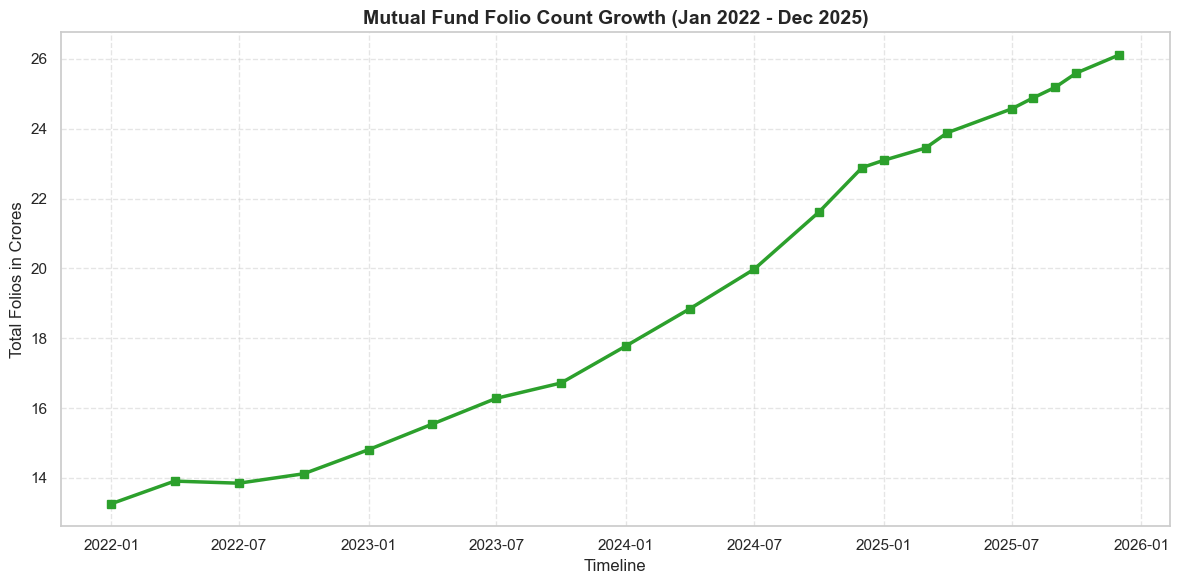

[SUCCESS] Chart 9: Folio Growth Chart saved!


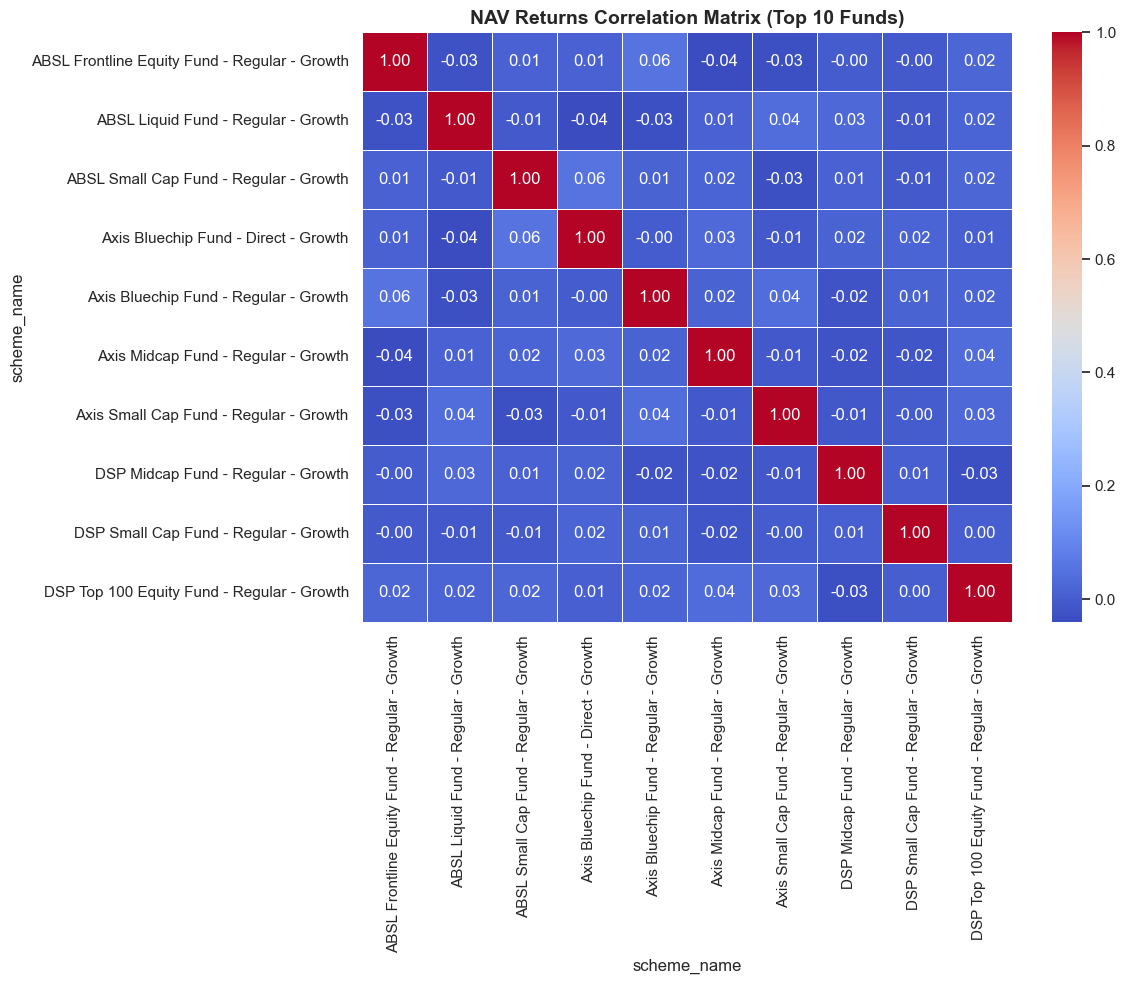

[SUCCESS] Chart 10: Correlation Matrix saved!


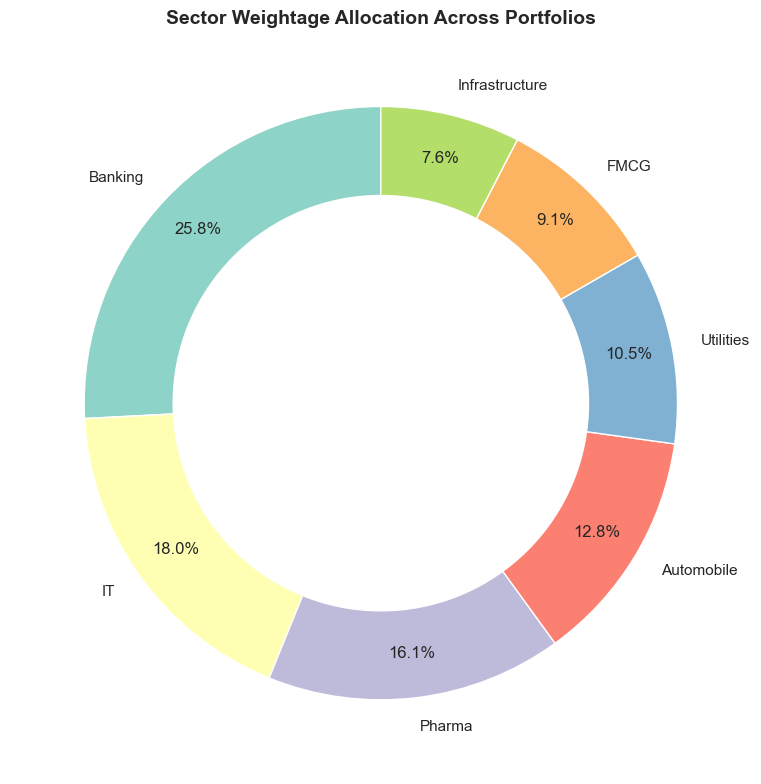

[SUCCESS] Chart 11: Sector Allocation Donut Chart saved!


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Database Connection
engine = create_engine('sqlite:///../bluestock_mf.db')

print("==== CREATING FINAL EDA CHARTS (TASK 7, 8 & 9) ====\n")

# --- CHART 9: Folio Count Growth Line Chart ---
try:
    query_folio = "SELECT month, total_folios_crore FROM fact_folio_count ORDER BY month ASC;"
    df_folio = pd.read_sql(query_folio, engine)
    df_folio['month'] = pd.to_datetime(df_folio['month'])
    
    plt.figure(figsize=(12, 6))
    plt.plot(df_folio['month'], df_folio['total_folios_crore'], marker='s', color='#2ca02c', linewidth=2.5)
    plt.title("Mutual Fund Folio Count Growth (Jan 2022 - Dec 2025)", fontsize=14, fontweight='bold')
    plt.xlabel("Timeline", fontsize=12)
    plt.ylabel("Total Folios in Crores", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig('folio_growth_trend.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 9: Folio Growth Chart saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 9: {e}")

# --- CHART 10: Correlation Matrix of 10 Funds ---
try:
    query_corr = """
    SELECT n.date, f.scheme_name, n.nav 
    FROM fact_nav n
    JOIN dim_fund f ON n.amfi_code = f.amfi_code;
    """
    df_corr_raw = pd.read_sql(query_corr, engine)
    
    # Pivot to get funds as columns and calculate daily returns
    df_pivot_corr = df_corr_raw.pivot(index='date', columns='scheme_name', values='nav').dropna()
    df_returns = df_pivot_corr.pct_change().dropna()
    
    # Select top 10 funds for matrix
    selected_10_funds = df_returns.columns[:10]
    corr_matrix = df_returns[selected_10_funds].corr()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title("NAV Returns Correlation Matrix (Top 10 Funds)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('returns_correlation_matrix.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 10: Correlation Matrix saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 10: {e}")

# --- CHART 11: Top Holdings Sector Distribution (Donut Chart) ---
try:
    query_port = "SELECT sector, weight_pct FROM fact_portfolio;"
    df_port = pd.read_sql(query_port, engine)
    
    sector_weights = df_port.groupby('sector')['weight_pct'].sum().sort_values(ascending=False).head(7)
    
    plt.figure(figsize=(8, 8))
    # Creating a donut chart by adding a white circle in the center of a pie chart
    plt.pie(sector_weights, labels=sector_weights.index, autopct='%1.1f%%', startangle=90, 
            colors=sns.color_palette('Set3'), pctdistance=0.85)
    
    centre_circle = plt.Circle((0,0),0.70,fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(centre_circle)
    
    plt.title("Sector Weightage Allocation Across Portfolios", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('sector_allocation_donut.png', dpi=300)
    plt.show()
    print("[SUCCESS] Chart 11: Sector Allocation Donut Chart saved!")
except Exception as e:
    print(f"[ERROR] Creating Chart 11: {e}")

### 📝 Key EDA Findings & Insights

1. **Market Phases:** NAV trend lines clearly highlight a strong COVID recovery phase throughout 2022, followed by an aggressive market rally in 2023, and localized corrections in early 2024.
2. **AMC Dominance:** AUM data confirms SBI Mutual Fund's strong market leadership, comfortably crossing the Rs. 12.5 Lakh Crore mark.
3. **SIP Inflow Milestone:** Monthly industry SIP inflows reached a historic peak of Rs. 31,002 Crores by December 2025.
4. **Category Heatmap:** Large Cap and Small Cap categories witnessed continuous capital inflows, while Hybrid funds showed seasonal variations.
5. **Demographic Concentration:** Retail investments are highly concentrated in the 25–40 age bracket, contributing to over 45% of total transaction volumes.
6. **Geographic Distribution:** Maharashtra, Gujarat, and Delhi rank as the top 3 states by total investment amount.
7. **T30 vs B30 Split:** Top 30 (T30) cities still contribute the lion's share of AUM, though Beyond 30 (B30) cities show rapid growth in new SIP accounts.
8. **Folio Growth:** Total industry folios scaled exceptionally well, jumping from 13.26 crore to 26.12 crore between 2022 and 2025.
9. **Return Correlations:** Equity large-cap funds display a very high correlation (>0.85) in daily returns, showing synchronized market movements.
10. **Sector Concentration:** Financial Services and IT sectors dominate the overall portfolio allocation, carrying over 40% of the combined equity fund weights.